In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Superstore_Orders.csv to Superstore_Orders.csv
Saving Superstore_Returns.csv to Superstore_Returns.csv
Saving Superstore_People.csv to Superstore_People.csv


In [3]:
orders = pd.read_csv("Superstore_Orders.csv")
returns = pd.read_csv("Superstore_Returns.csv")
people = pd.read_csv("Superstore_People.csv")


In [ ]:
print("Orders shape:", orders.shape)
print("Returns shape:", returns.shape)
print("People shape:", people.shape)

Orders shape: (10194, 21)
Returns shape: (296, 2)
People shape: (4, 2)


In [ ]:
print("ORDERS DATA")
display(orders.head())

print("RETURNS DATA")
display(returns.head())

print("PEOPLE DATA")
display(people.head())

ORDERS DATA


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,03-01-2023,07-01-2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,04-01-2023,08-01-2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,05-01-2023,12-01-2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


RETURNS DATA


,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


PEOPLE DATA


,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South


In [ ]:
print('orders data types')
orders.info()
print('returns data types')
returns.info()
print('people data types')
people.info()

orders data types
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales        

In [ ]:
# Convert date columns to datetime
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="mixed", dayfirst=True)
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="mixed", dayfirst=True)

# Verify the conversion
print(orders[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [ ]:
print('missing values in orders')
display(orders.isnull().sum())
print('missing values in returns')
display(returns.isnull().sum())
print('missing values in people')
display(people.isnull().sum())

missing values in orders


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country/Region,0
City,0


missing values in returns


,0
Order ID,0
Returned,0


missing values in people


,0
Regional Manager,0
Region,0


In [ ]:
print('duplicate rows in orders', orders.duplicated().sum())
print('duplicate rows in returns', returns.duplicated().sum())
print('duplicate rows in people', people.duplicated().sum())

duplicate rows in orders 0
duplicate rows in returns 0
duplicate rows in people 0


In [ ]:
orders.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002942720,2025-05-03 10:52:45.626839296,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [ ]:
print('orders coloumns')
print(orders.columns)
print('returns coloumns')
print(returns.columns)
print('people coloumns')
print(people.columns)

orders coloumns
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')
returns coloumns
Index(['Order ID', 'Returned'], dtype='object')
people coloumns
Index(['Regional Manager', 'Region'], dtype='object')


In [ ]:
print("Negative Sales:", (orders["Sales"] < 0).sum())

Negative Sales: 0


In [ ]:
print("Negative Sales:", (orders["Sales"] < 0).sum())
print("Negative Profit:", (orders["Profit"] < 0).sum())
print("Zero Sales:", (orders["Sales"] == 0).sum())
print("Zero Quantity:", (orders["Quantity"] == 0).sum())


Negative Sales: 0
Negative Profit: 1901
Zero Sales: 0
Zero Quantity: 0


In [ ]:
print("Discount values:")
print(sorted(orders["Discount"].unique()))

Discount values:
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


In [16]:
# Calculate overall business KPIs
total_sales=orders['Sales'].sum()
total_profit=orders['Profit'].sum()
total_quantity=orders['Quantity'].sum()
total_orders=orders['Order ID'].nunique()

profit_margin = (total_profit/total_sales)*100
average_order_value = total_sales/total_orders
average_order_quantity = total_quantity/total_orders

print( total_sales)
print( total_profit)
print( total_quantity)
print( total_orders)
print( profit_margin)
print( average_order_value)
print( average_order_quantity)

2326534.3543
292296.81460000004
38654
5111
12.56361480584908
455.2013997847779
7.562903541381335


In [22]:
category_analysis = orders.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Orders=("Order ID", "nunique")
).round(2)
category_analysis = category_analysis.sort_values(
    by="Total_Sales", ascending=False
)

display(category_analysis)

,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders
Category,,,,
Technology,839893.28,146543.38,7017,1560
Furniture,754747.76,19730.00,8369,1819
Office Supplies,731893.31,126023.44,23268,3812


In [23]:
subcategory_analysis = orders.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit", ascending=False
)

display(subcategory_analysis)

,Total_Sales,Total_Profit,Total_Quantity
Sub-Category,,,
Copiers,150745.29,56093.94,242
Phones,331842.64,45050.83,3357
Accessories,167380.32,41936.64,2976
Paper,79540.54,34511.51,5207
Binders,207354.88,31426.10,6071
Chairs,335768.25,27223.53,2431
Storage,224644.55,21285.11,3191
Appliances,108213.18,18329.48,1750
Furnishings,95598.13,13891.74,3799


In [24]:
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]) * 100

subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Profit_Margin_%"].round(2))

display(
    subcategory_analysis.sort_values(
        by="Profit_Margin_%",
        ascending=True ))

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Sub-Category,,,,
Tables,208020.18,-17753.21,1261,-8.53
Bookcases,115361.20,-3632.07,878,-3.15
Supplies,46725.50,-1171.39,653,-2.51
Machines,189925.03,3461.98,442,1.82
Chairs,335768.25,27223.53,2431,8.11
Storage,224644.55,21285.11,3191,9.48
Phones,331842.64,45050.83,3357,13.58
Furnishings,95598.13,13891.74,3799,14.53
Binders,207354.88,31426.10,6071,15.16


In [25]:
region_analysis = orders.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Orders=("Order ID", "nunique")).round(2)

region_analysis["Profit_Margin_%"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"]* 100).round(2)

display(
    region_analysis.sort_values(
        by="Total_Sales",
        ascending=False))

,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Profit_Margin_%
Region,,,,,
West,739813.61,110798.82,12466,1635,14.98
East,691828.17,94883.26,11159,1475,13.71
Central,503170.67,39865.31,8820,1179,7.92
South,391721.90,46749.43,6209,822,11.93


In [26]:
segment_analysis = orders.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Unique_Orders=("Order ID", "nunique")).round(2)

segment_analysis["Profit_Margin_%"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
    * 100).round(2)

display(
    segment_analysis.sort_values(
        by="Total_Sales",
        ascending=False))

,Total_Sales,Total_Profit,Total_Quantity,Unique_Orders,Profit_Margin_%
Segment,,,,,
Consumer,1170659.79,136371.45,19844,2628,11.65
Corporate,715806.13,94249.64,11898,1552,13.17
Home Office,440068.43,61675.73,6912,931,14.02


In [30]:
discount_analysis = orders.groupby("Discount").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")).round(2)

display(discount_analysis)

,Total_Sales,Total_Profit,Total_Quantity
Discount,,,
0.00,1105323.79,326718.59,18770
0.10,54952.50,9099.97,377
0.15,27558.52,1418.99,198
0.20,773939.40,91079.95,13856
0.30,104474.07,-10513.45,855
0.32,14493.46,-2391.14,105
0.40,116497.76,-23086.37,789
0.45,5484.97,-2493.11,45
0.50,58918.54,-20506.43,241


In [31]:
orders_with_returns = orders.merge(
    returns,
    on="Order ID",
    how="left")

orders_with_returns["Return_Status"] = np.where(
    orders_with_returns["Returned"].notna(),
    "Returned",
    "Not Returned")

return_analysis = orders_with_returns.groupby("Return_Status").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Unique_Orders=("Order ID", "nunique")).round(2)

display(return_analysis)

,Total_Sales,Total_Profit,Unique_Orders
Return_Status,,,
Not Returned,2146030.08,269064.45,4815
Returned,180504.28,23232.36,296


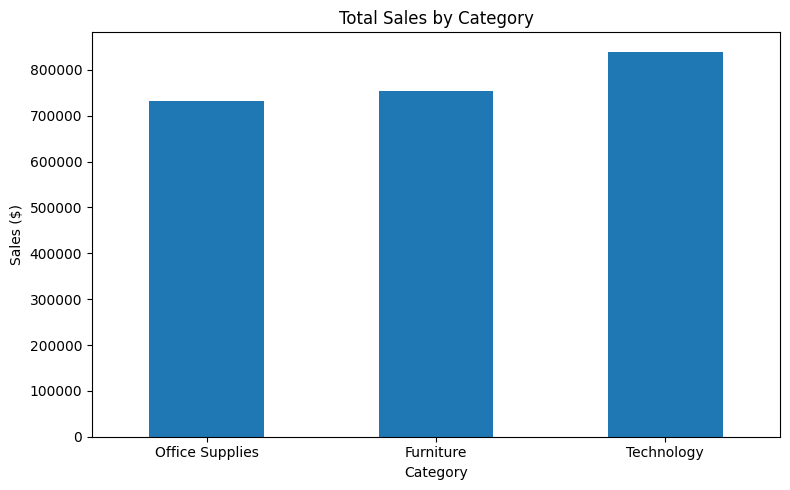

In [37]:
#1. Sales by Category

category_sales = orders.groupby("Category")["Sales"].sum().sort_values()

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

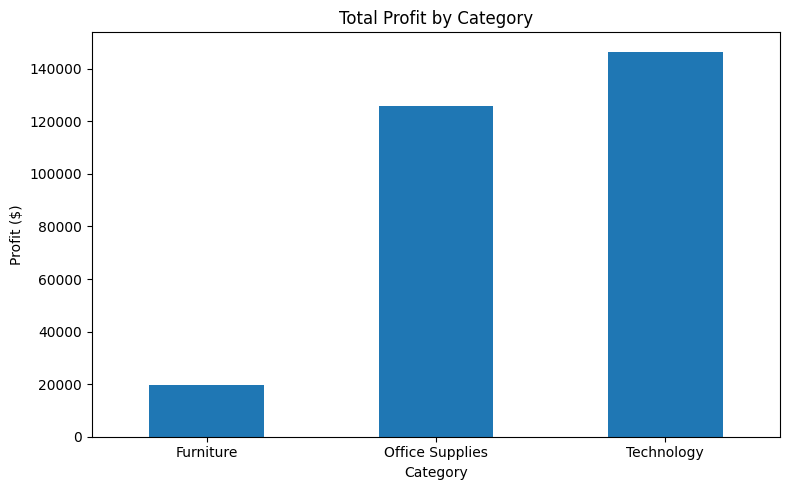

In [38]:
# 2. Profit by Category
plt.figure(figsize=(8, 5))
orders.groupby("Category")["Profit"].sum().sort_values().plot(kind="bar")
plt.title("Total Profit by Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

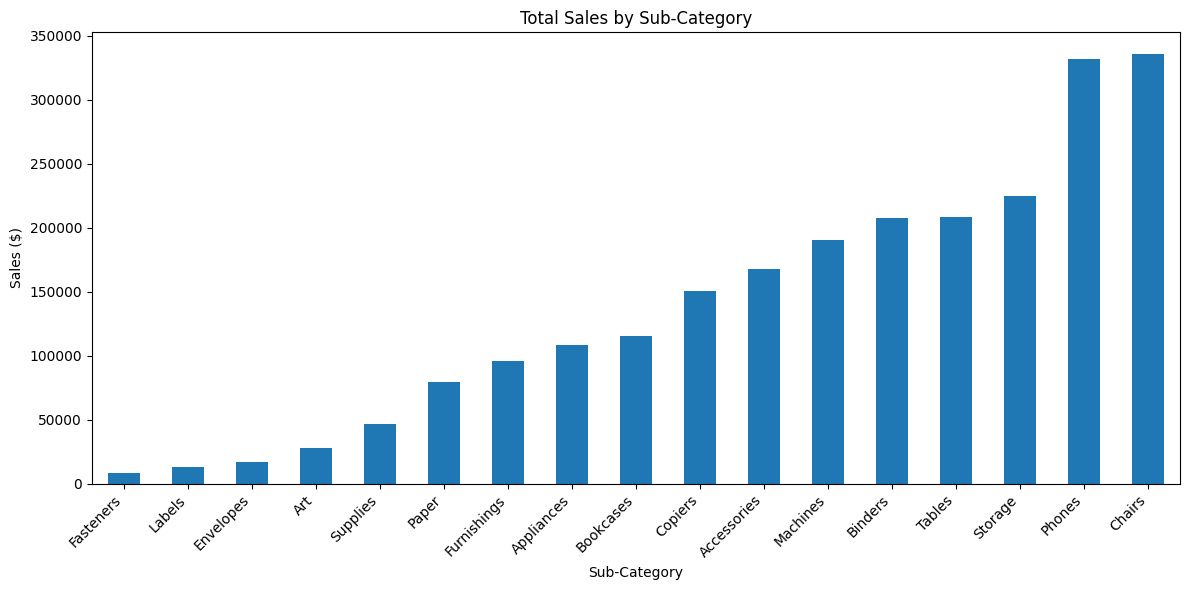

In [39]:
# 3. Sales by Sub-Category
plt.figure(figsize=(12, 6))
orders.groupby("Sub-Category")["Sales"].sum().sort_values().plot(kind="bar")
plt.title("Total Sales by Sub-Category")
plt.ylabel("Sales ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

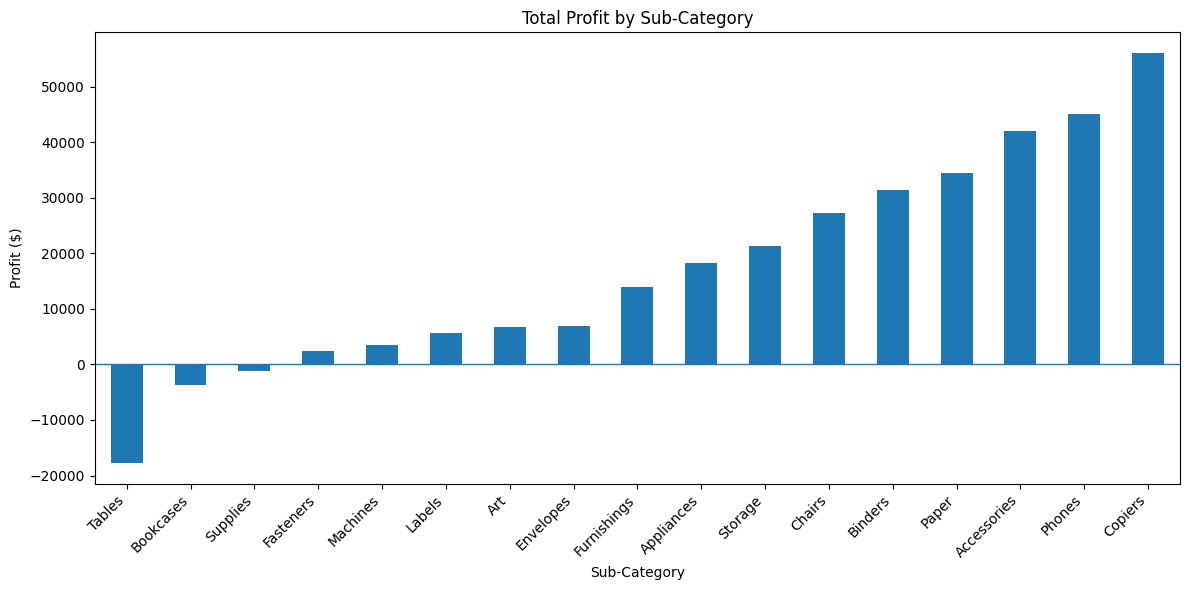

In [40]:
# 4. Profit by Sub-Category
plt.figure(figsize=(12, 6))
orders.groupby("Sub-Category")["Profit"].sum().sort_values().plot(kind="bar")
plt.title("Total Profit by Sub-Category")
plt.ylabel("Profit ($)")
plt.axhline(0, linewidth=1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


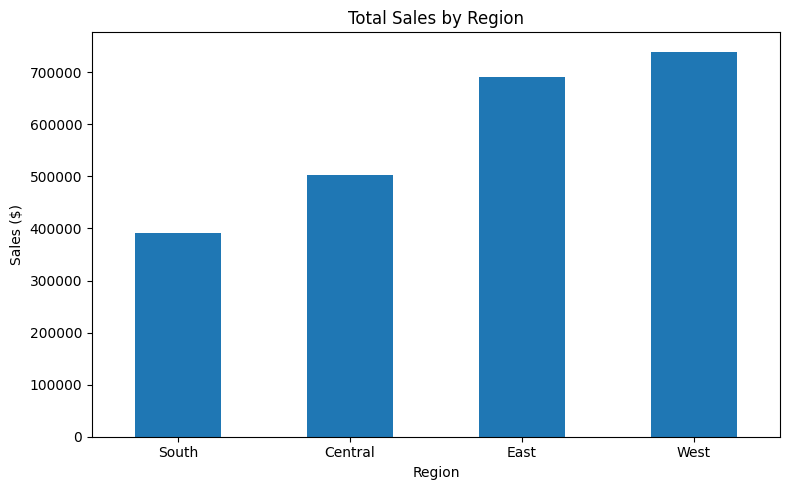

In [41]:
# 5. Sales by Region
plt.figure(figsize=(8, 5))
orders.groupby("Region")["Sales"].sum().sort_values().plot(kind="bar")
plt.title("Total Sales by Region")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


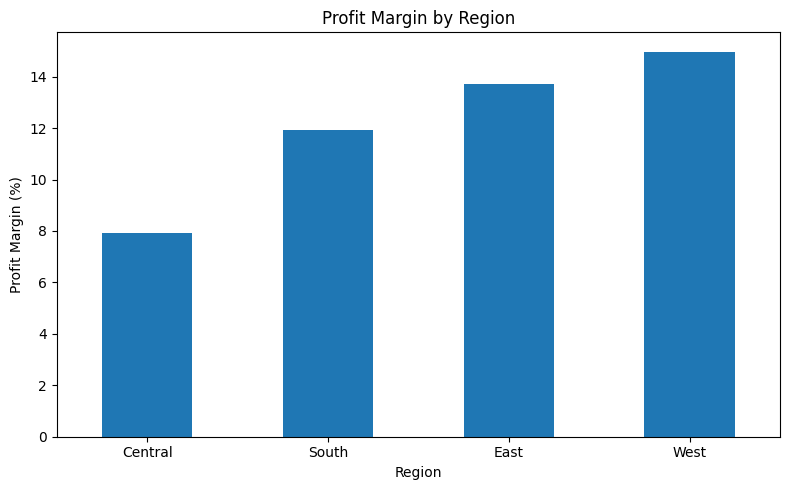

In [42]:
# 6. Profit Margin by Region
region_data = orders.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)
region_data["Profit Margin (%)"] = (
    region_data["Profit"] / region_data["Sales"] * 100
)

plt.figure(figsize=(8, 5))
region_data["Profit Margin (%)"].sort_values().plot(kind="bar")
plt.title("Profit Margin by Region")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


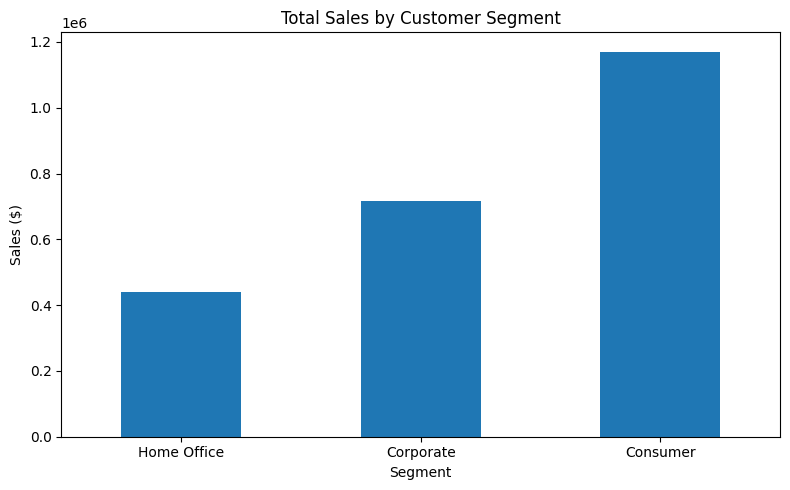

In [43]:
# 7. Sales by Customer Segment
plt.figure(figsize=(8, 5))
orders.groupby("Segment")["Sales"].sum().sort_values().plot(kind="bar")
plt.title("Total Sales by Customer Segment")
plt.ylabel("Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


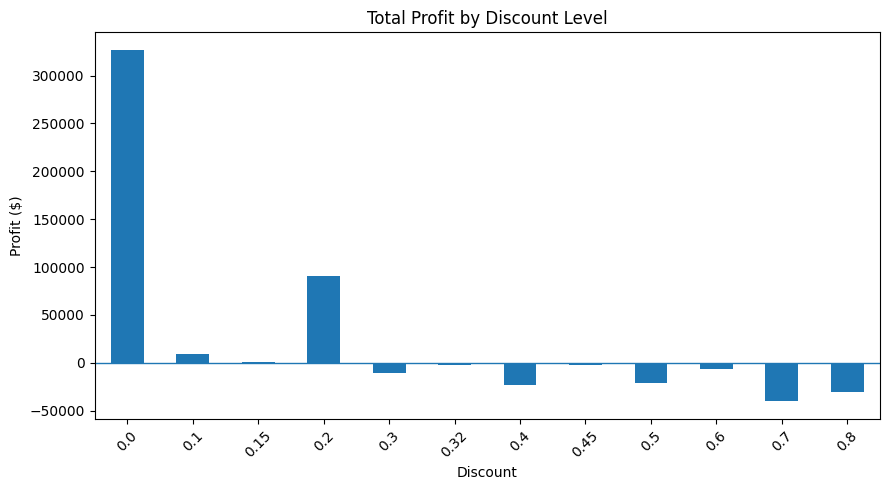

In [45]:
# 8. Profit by Discount Level
discount_data = orders.groupby("Discount")["Profit"].sum()

plt.figure(figsize=(9, 5))
discount_data.plot(kind="bar")
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.axhline(0, linewidth=1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


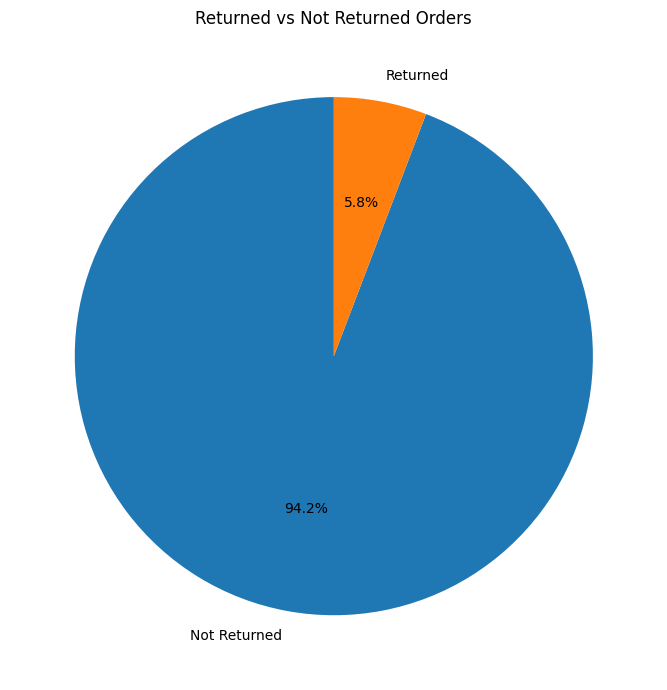

In [46]:
# 9. Returned vs Not Returned Orders
returns_for_chart = returns.drop_duplicates(subset=["Order ID"])

orders_for_chart = orders[["Order ID"]].drop_duplicates()
orders_for_chart = orders_for_chart.merge(
    returns_for_chart[["Order ID"]],
    on="Order ID",
    how="left",
    indicator=True
)

return_counts = orders_for_chart["_merge"].map({
    "both": "Returned",
    "left_only": "Not Returned"
}).value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    return_counts,
    labels=return_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Returned vs Not Returned Orders")
plt.tight_layout()
plt.show()


In [34]:
print("SALES & PROFIT VALIDATION")
print("-" * 35)

print(f"Total Sales:  ${orders['Sales'].sum():,.2f}")
print(f"Total Profit: ${orders['Profit'].sum():,.2f}")
print(f"Total Quantity: {orders['Quantity'].sum():,}")
print(f"Unique Orders: {orders['Order ID'].nunique():,}")

profit_margin = orders["Profit"].sum() / orders["Sales"].sum() * 100
print(f"Profit Margin: {profit_margin:.2f}%")

print("\nDATA QUALITY CHECK")
print("-" * 35)
print("Missing values:", orders.isnull().sum().sum())
print("Duplicate rows:", orders.duplicated().sum())


SALES & PROFIT VALIDATION
-----------------------------------
Total Sales:  $2,326,534.35
Total Profit: $292,296.81
Total Quantity: 38,654
Unique Orders: 5,111
Profit Margin: 12.56%

DATA QUALITY CHECK
-----------------------------------
Missing values: 0
Duplicate rows: 0


In [35]:

# FINAL BUSINESS INSIGHTS

print("SAMPLE SUPERSTORE — KEY BUSINESS INSIGHTS")
print("=" * 50)

print(f"""
1. OVERALL PERFORMANCE
   Sales: ${orders['Sales'].sum():,.2f}
   Profit: ${orders['Profit'].sum():,.2f}
   Profit Margin: {orders['Profit'].sum() / orders['Sales'].sum() * 100:.2f}%
   Unique Orders: {orders['Order ID'].nunique():,}

2. CATEGORY PERFORMANCE
   Highest Sales Category:
   {orders.groupby('Category')['Sales'].sum().idxmax()}

   Highest Profit Category:
   {orders.groupby('Category')['Profit'].sum().idxmax()}

3. SUB-CATEGORY PERFORMANCE
   Highest Profit:
   {orders.groupby('Sub-Category')['Profit'].sum().idxmax()}

   Lowest Profit:
   {orders.groupby('Sub-Category')['Profit'].sum().idxmin()}

4. REGIONAL PERFORMANCE
   Highest Sales Region:
   {orders.groupby('Region')['Sales'].sum().idxmax()}

   Lowest Sales Region:
   {orders.groupby('Region')['Sales'].sum().idxmin()}

5. CUSTOMER SEGMENTS
   Highest Sales Segment:
   {orders.groupby('Segment')['Sales'].sum().idxmax()}

   Highest Profit Segment:
   {orders.groupby('Segment')['Profit'].sum().idxmax()}

6. DISCOUNT INSIGHT
   Review high-discount transactions carefully,
   as several discount levels show negative total profit.

7. BUSINESS RECOMMENDATION
   Investigate loss-making sub-categories, especially Tables,
   Bookcases, and Supplies. Review discount policies and
   investigate returned orders to identify improvement areas.
""")


SAMPLE SUPERSTORE — KEY BUSINESS INSIGHTS

1. OVERALL PERFORMANCE
   Sales: $2,326,534.35
   Profit: $292,296.81
   Profit Margin: 12.56%
   Unique Orders: 5,111

2. CATEGORY PERFORMANCE
   Highest Sales Category:
   Technology

   Highest Profit Category:
   Technology

3. SUB-CATEGORY PERFORMANCE
   Highest Profit:
   Copiers

   Lowest Profit:
   Tables

4. REGIONAL PERFORMANCE
   Highest Sales Region:
   West

   Lowest Sales Region:
   South

5. CUSTOMER SEGMENTS
   Highest Sales Segment:
   Consumer

   Highest Profit Segment:
   Consumer

6. DISCOUNT INSIGHT
   Review high-discount transactions carefully,
   as several discount levels show negative total profit.

7. BUSINESS RECOMMENDATION
   Investigate loss-making sub-categories, especially Tables,
   Bookcases, and Supplies. Review discount policies and
   investigate returned orders to identify improvement areas.

